# Demo: Unterrichtsblock 6

Kurze Transferdemo für univariate Statistiken und Resampling.

Du arbeitest hier mit Solarpanel-Daten in `15min`-Auflösung. Anschliessend bearbeitest du selbstständig `01-univariate-eda.ipynb` und `02-upsampling-downsampling.ipynb`.

Relevante Artikel in der Wissensdatenbank:

- [Wissensdatenbank: Univariate Statistiken](https://abbts-dat-ski.github.io/wissensdatenbank/statistics/univariate_statistics/)
- [Wissensdatenbank: Resampling](https://abbts-dat-ski.github.io/wissensdatenbank/data-engineering/resampling/)

In [1]:
import pandas as pd


In [2]:
df = pd.read_csv("../data/ub6_demo_solar_day.csv")
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"], format="%d-%m-%Y %H:%M")
df = df.sort_values("DATE_TIME").set_index("DATE_TIME")

df.head()

,DC_POWER,AC_POWER
DATE_TIME,,
2020-05-30 00:00:00,0.0,0.0
2020-05-30 00:15:00,0.0,0.0
2020-05-30 00:30:00,0.0,0.0
2020-05-30 00:45:00,0.0,0.0
2020-05-30 01:00:00,0.0,0.0


### Aufgabe 1

Berechne für `AC_POWER` und `DC_POWER` die deskriptiven Statistiken.

Beantworte anschliessend kurz:

- Welche Spalte hat den höheren Mittelwert?
- Welche Spalte streut stärker?
- Mittelwert und Median vergleichen

In [3]:
df[["AC_POWER", "DC_POWER"]].head()

,AC_POWER,DC_POWER
DATE_TIME,,
2020-05-30 00:00:00,0.0,0.0
2020-05-30 00:15:00,0.0,0.0
2020-05-30 00:30:00,0.0,0.0
2020-05-30 00:45:00,0.0,0.0
2020-05-30 01:00:00,0.0,0.0


In [4]:
# Dein Code hier
df.describe()

,DC_POWER,AC_POWER
count,96.000000,96.000000
mean,2879.863467,281.819717
std,3799.475058,371.472473
min,0.000000,0.000000
25%,0.000000,0.000000
50%,285.741071,27.590179
75%,5065.705357,496.661161
max,12998.428570,1267.728571


### Aufgabe 2

Verdichte die Zeitreihe von `15min` auf `1h`.

Verwende eine passende Aggregation für `AC_POWER` und prüfe das Ergebnis anschliessend mit einem einfachen Plot (`df.plot()`).

In [5]:
# Dein Code hier
df.resample("1h").mean()
df

,DC_POWER,AC_POWER
DATE_TIME,,
2020-05-30 00:00:00,0.0,0.0
2020-05-30 00:15:00,0.0,0.0
2020-05-30 00:30:00,0.0,0.0
2020-05-30 00:45:00,0.0,0.0
2020-05-30 01:00:00,0.0,0.0
...,...,...
2020-05-30 22:45:00,0.0,0.0
2020-05-30 23:00:00,0.0,0.0
2020-05-30 23:15:00,0.0,0.0


### Aufgabe 3

Erhöhe die stündliche Reihe wieder auf `30min`.

Fülle die neu entstehenden Zwischenwerte auf zwei Arten und vergleiche die Resultate in einem einfachen Plot.

- zuerst nur das neue Zeitraster ansehen
- `resample` erzeugt Zeilen, gefüllt wird erst danach

In [8]:
df_resampled = df.resample("30min").interpolate(method="linear")

<Axes: xlabel='DATE_TIME'>

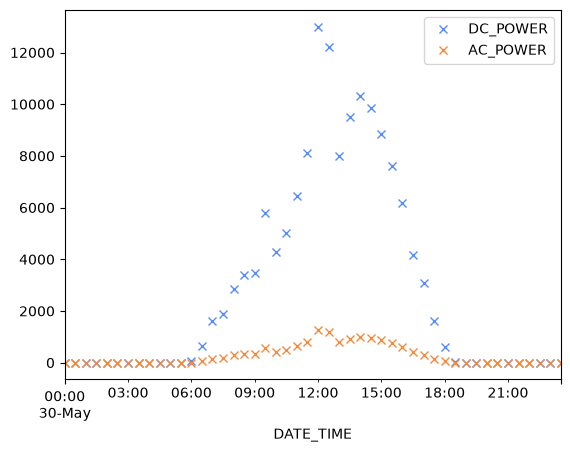

In [9]:
df_resampled.plot(style="x")